# Compilation reports and engine exports

Inspect epJSON, compilation settings and IDF export as explicit boundaries of the simulation pipeline.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`EnergyPlusCompiler` resolves an explicit building into engine objects. `compile` returns an in-memory model and report; `write` emits the model, original building and compilation report to a chosen directory. `CompilerSettings` contains engine controls that also participate in simulation identity.

The geometry-pipeline figure maps domain inputs into emitted surfaces and shows why logical openings, thermal parents and physical quantities retain separate meanings. IDF export is another engine interchange form of the compiled input. It does not replace the original `BuildingSpec` or its provenance.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Compile with explicit settings

CompilerSettings adds keyed hourly outputs and participates in run identity. Physical simulation settings are fixed and validated.

### Read the code and output

The shadow-figure setting controls an engine workload limit, not the radius or number of neighbours. Check `len(model["Zone"])` for zones and object-type inventories for emitted complexity. Increasing a limit should not be interpreted as evidence that arbitrary scene complexity is appropriate for stock modelling.

Reference: [Existing viewer controls and target/context separation](../../docs/figures/viewer-controls.png). This linked documentation illustration is separate from the outputs computed below.

,field,value
0,run_id,bfdab19c40dbf52e5a40c1a9b0e9ed9a010a566da7ced7...
1,model_types,37
2,zones,3


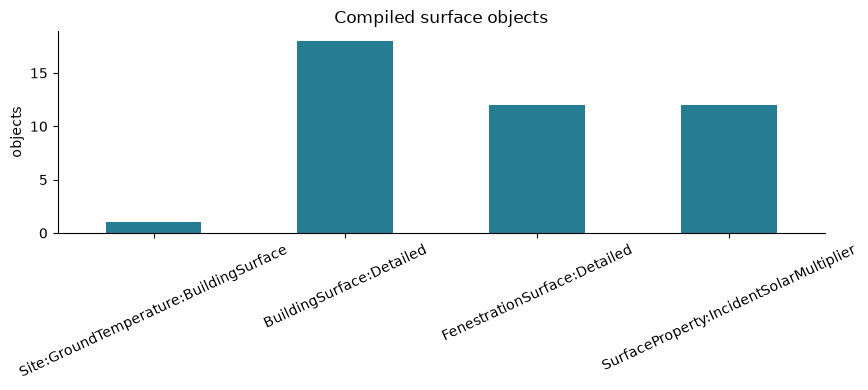

In [2]:
b=building()
settings=CompilerSettings(hourly_outputs=(HourlyOutputRequest(name="Site Outdoor Air Drybulb Temperature"),))
compiler=EnergyPlusCompiler(engine(),settings=settings)
model,report=compiler.compile(b)
assert isinstance(report,CompilationReport)
table({"run_id":report.run_id,"model_types":len(model),"zones":len(model["Zone"])})
bars({k:len(v) for k,v in model.items() if "Surface" in k},"objects","Compiled surface objects")

## Write inspectable engine artifacts

The compiler writes building.json, model.epJSON and compilation.json. Its report records actual generated quantities and validation evidence.

### Read the code and output

Use the adjacent `compilation.json` to interpret a surface selected in the compiled widget. A geometry-only preview cannot provide assigned construction layers that were never attached. Matching report/run identities verifies that the written evidence describes the intended compilation.

In [3]:
written=compiler.write(b,OUT/"compiled")
assert written.run_id==report.run_id
assert compiler.run_id(b)==report.run_id
table([{ "artifact":p.name,"bytes":p.stat().st_size} for p in (OUT/"compiled").iterdir()])
from epsm_core.viewer import widget_epjson
display(widget_epjson(OUT/"compiled/model.epJSON"))

,artifact,bytes
0,building.json,39071
1,model.epJSON,66780
2,compilation.json,31228


## Exercise CLI compile and IDF export

IDF is an engine interchange artifact, not a replacement for the explicit BuildingSpec. Check the CLI output and retain the original spec and report.

### Read the code and output

The CLI compile and export commands provide a reproducible boundary for external callers. The resulting IDF is a generated artifact; edits there are not automatically reflected in the immutable Python input. Keep the original input and report as the auditable description of the case.

In [4]:
import subprocess
spec_path=OUT/"compiled/building.json"
for args in [["compile",str(spec_path),str(OUT/"cli-compiled")],["export-idf",str(spec_path),str(OUT/"idf")]]:
    proc=subprocess.run([sys.executable,"-m","epsm_core.cli","--energyplus",engine(),*args],capture_output=True,text=True,check=True)
    print(proc.stdout[:800])

EnergyPlus Starting
EnergyPlus, Version 24.2.0-94a887817b, YMD=2026.09.07 11:00
Converted input file format. Exiting.
EnergyPlus Run Time=00hr 00min  0.03sec



## Interpretation and next experiment

Keep compiler, backend and engine identities with inputs. Compilation success proves model acceptance checks, not an annual simulation outcome.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.